In [2]:
print("Jupyter 작동 확인")

import pandas as pd
print("pandas OK")

import numpy as np
print("numpy OK")

import matplotlib.pyplot as plt
print("matplotlib OK")

Jupyter 작동 확인
pandas OK
numpy OK


Matplotlib is building the font cache; this may take a moment.


matplotlib OK


In [3]:
from pathlib import Path

cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_DIR = cwd.parent
else:
    PROJECT_DIR = cwd

DATA_DIR = PROJECT_DIR / "data" / "raw"

print("현재 위치:", cwd)
print("데이터 폴더:", DATA_DIR)

현재 위치: c:\Users\psj85\OneDrive\문서\바탕 화면\머신러닝 스터디\SECOM_PCA\notebooks
데이터 폴더: c:\Users\psj85\OneDrive\문서\바탕 화면\머신러닝 스터디\SECOM_PCA\data\raw


In [4]:
X = pd.read_csv(
    DATA_DIR / "secom.data",
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    DATA_DIR / "secom_labels.data",
    sep=r"\s+",
    header=None
)

y = labels.iloc[:, 0].copy()

print("X shape:", X.shape)
print("labels shape:", labels.shape)
print("\n라벨 분포:")
print(y.value_counts())

X shape: (1567, 590)
labels shape: (1567, 2)

라벨 분포:
0
-1    1463
 1     104
Name: count, dtype: int64


In [6]:
print("샘플 수:", X.shape[0])
print("센서 변수 수:", X.shape[1])

print("\n전체 결측값 수:", X.isna().sum().sum())

missing_ratio = X.isna().mean()

print("결측값이 있는 변수 수:", (missing_ratio > 0).sum())
print("결측률 50% 이상 변수 수:", (missing_ratio >= 0.5).sum())

샘플 수: 1567
센서 변수 수: 590

전체 결측값 수: 41951
결측값이 있는 변수 수: 538
결측률 50% 이상 변수 수: 28


In [7]:
missing_summary = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_ratio": X.isna().mean()
})

missing_summary = missing_summary.sort_values(
    "missing_ratio",
    ascending=False
)

missing_summary.head(15)

,missing_count,missing_ratio
292,1429,0.911934
293,1429,0.911934
158,1429,0.911934
157,1429,0.911934
492,1341,0.855775
85,1341,0.855775
358,1341,0.855775
220,1341,0.855775
244,1018,0.649649
517,1018,0.649649


In [8]:
unique_counts = X.nunique(dropna=True)

constant_cols = unique_counts[unique_counts <= 1].index.tolist()

print("상수 또는 값이 하나뿐인 변수 수:", len(constant_cols))
print("변수 번호:", constant_cols)

상수 또는 값이 하나뿐인 변수 수: 116
변수 번호: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]


In [9]:
class_counts = y.value_counts().sort_index()

print("라벨 개수:")
print(class_counts)

print("\n라벨 비율:")
print((y.value_counts(normalize=True) * 100).round(2))

라벨 개수:
0
-1    1463
 1     104
Name: count, dtype: int64

라벨 비율:
0
-1    93.36
 1     6.64
Name: proportion, dtype: float64


In [10]:
label_name = y.map({
    -1: "Pass",
     1: "Fail"
})

print(label_name.value_counts())
print()
print((label_name.value_counts(normalize=True) * 100).round(2))

0
Pass    1463
Fail     104
Name: count, dtype: int64

0
Pass    93.36
Fail     6.64
Name: proportion, dtype: float64


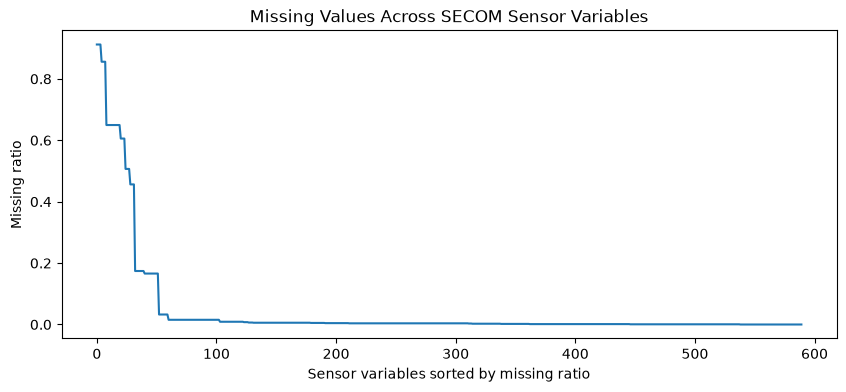

In [11]:
missing_ratio_sorted = missing_ratio.sort_values(ascending=False)

plt.figure(figsize=(10, 4))
plt.plot(range(len(missing_ratio_sorted)), missing_ratio_sorted.values)

plt.xlabel("Sensor variables sorted by missing ratio")
plt.ylabel("Missing ratio")
plt.title("Missing Values Across SECOM Sensor Variables")

plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nTrain 라벨:")
print(y_train.value_counts())

print("\nTest 라벨:")
print(y_test.value_counts())

X_train: (1253, 590)
X_test : (314, 590)

Train 라벨:
0
-1    1170
 1      83
Name: count, dtype: int64

Test 라벨:
0
-1    293
 1     21
Name: count, dtype: int64


In [13]:
train_missing_ratio = X_train.isna().mean()

high_missing_cols = train_missing_ratio[
    train_missing_ratio >= 0.5
].index.tolist()

print("Train 기준 결측률 50% 이상 변수 수:", len(high_missing_cols))
print("제거 변수:", high_missing_cols[:20])

Train 기준 결측률 50% 이상 변수 수: 24
제거 변수: [85, 109, 110, 111, 157, 158, 220, 244, 245, 246, 292, 293, 358, 382, 383, 384, 492, 516, 517, 518]


In [14]:
X_train_clean = X_train.drop(columns=high_missing_cols)
X_test_clean = X_test.drop(columns=high_missing_cols)

print("제거 전:", X_train.shape)
print("제거 후:", X_train_clean.shape)

제거 전: (1253, 590)
제거 후: (1253, 566)


In [21]:
train_unique_counts = X_train_clean.nunique(dropna=True)

constant_cols_train = train_unique_counts[
    train_unique_counts <= 1
].index.tolist()

print("Train 기준 상수 변수 수:", len(constant_cols_train))
print("상수 변수 예시:", constant_cols_train[:20])

Train 기준 상수 변수 수: 0
상수 변수 예시: []


In [22]:
X_train_clean = X_train_clean.drop(columns=constant_cols_train)
X_test_clean = X_test_clean.drop(columns=constant_cols_train)

print("상수 변수 제거 후 Train:", X_train_clean.shape)
print("상수 변수 제거 후 Test :", X_test_clean.shape)

상수 변수 제거 후 Train: (1253, 450)
상수 변수 제거 후 Test : (314, 450)


In [23]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_clean)
X_test_imputed = imputer.transform(X_test_clean)

print("결측치 처리 후 Train 결측값:",
      np.isnan(X_train_imputed).sum())

print("결측치 처리 후 Test 결측값:",
      np.isnan(X_test_imputed).sum())

print("Train shape:", X_train_imputed.shape)
print("Test shape :", X_test_imputed.shape)

결측치 처리 후 Train 결측값: 0
결측치 처리 후 Test 결측값: 0
Train shape: (1253, 450)
Test shape : (314, 450)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("표준화 완료")
print("Train shape:", X_train_scaled.shape)
print("Test shape :", X_test_scaled.shape)

print("\nTrain 평균:",
      X_train_scaled.mean().round(6))

print("Train 표준편차:",
      X_train_scaled.std().round(6))

표준화 완료
Train shape: (1253, 450)
Test shape : (314, 450)

Train 평균: -0.0
Train 표준편차: 1.0


In [25]:
# Train 기준 결측률 50% 이상 변수 찾기
train_missing_ratio = X_train.isna().mean()

high_missing_cols = train_missing_ratio[
    train_missing_ratio >= 0.5
].index.tolist()

# 1단계: 고결측 변수 제거
X_train_hm = X_train.drop(columns=high_missing_cols)
X_test_hm = X_test.drop(columns=high_missing_cols)

print("고결측 변수 수:", len(high_missing_cols))
print("고결측 제거 후:", X_train_hm.shape)

고결측 변수 수: 24
고결측 제거 후: (1253, 566)


In [26]:
# 2단계: Train 기준 상수 변수 찾기
train_unique_counts = X_train_hm.nunique(dropna=True)

constant_cols_train = train_unique_counts[
    train_unique_counts <= 1
].index.tolist()

print("상수 변수 수:", len(constant_cols_train))

상수 변수 수: 116


In [27]:
# 2단계: 상수 변수 제거
X_train_clean = X_train_hm.drop(columns=constant_cols_train)
X_test_clean = X_test_hm.drop(columns=constant_cols_train)

print("최종 Train:", X_train_clean.shape)
print("최종 Test :", X_test_clean.shape)

최종 Train: (1253, 450)
최종 Test : (314, 450)


In [28]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_clean)
X_test_imputed = imputer.transform(X_test_clean)

print("Train 결측값:", np.isnan(X_train_imputed).sum())
print("Test 결측값 :", np.isnan(X_test_imputed).sum())

print("Train shape:", X_train_imputed.shape)
print("Test shape :", X_test_imputed.shape)

Train 결측값: 0
Test 결측값 : 0
Train shape: (1253, 450)
Test shape : (314, 450)


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("표준화 완료")

print("Train shape:", X_train_scaled.shape)
print("Test shape :", X_test_scaled.shape)

print("Train 평균:", X_train_scaled.mean().round(6))
print("Train 표준편차:", X_train_scaled.std().round(6))

표준화 완료
Train shape: (1253, 450)
Test shape : (314, 450)
Train 평균: -0.0
Train 표준편차: 1.0


## 3. PCA 적용 전 Baseline 모델

전처리된 450개 변수를 그대로 사용하여 Logistic Regression을 학습한다.
이후 동일한 모델에 PCA를 적용하여 성능 변화를 비교한다.

In [30]:
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 클래스 불균형을 고려한 Logistic Regression
baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    random_state=42
)

# 학습 시간 측정
start_time = time.perf_counter()

baseline_model.fit(X_train_scaled, y_train)

baseline_train_time = time.perf_counter() - start_time

# 예측
y_pred_baseline = baseline_model.predict(X_test_scaled)

# Fail(1)일 확률
fail_idx = list(baseline_model.classes_).index(1)
y_prob_baseline = baseline_model.predict_proba(X_test_scaled)[:, fail_idx]

print("Baseline 학습 완료")
print("학습 시간:", round(baseline_train_time, 4), "초")

Baseline 학습 완료
학습 시간: 0.0966 초


In [31]:
baseline_accuracy = accuracy_score(
    y_test,
    y_pred_baseline
)

baseline_bal_acc = balanced_accuracy_score(
    y_test,
    y_pred_baseline
)

baseline_recall = recall_score(
    y_test,
    y_pred_baseline,
    pos_label=1
)

baseline_f1 = f1_score(
    y_test,
    y_pred_baseline,
    pos_label=1
)

baseline_auc = roc_auc_score(
    (y_test == 1).astype(int),
    y_prob_baseline
)

print("=== PCA 적용 전 Baseline ===")
print(f"Accuracy          : {baseline_accuracy:.4f}")
print(f"Balanced Accuracy : {baseline_bal_acc:.4f}")
print(f"Fail Recall       : {baseline_recall:.4f}")
print(f"Fail F1-score     : {baseline_f1:.4f}")
print(f"ROC-AUC           : {baseline_auc:.4f}")
print(f"Train Time        : {baseline_train_time:.4f} sec")

=== PCA 적용 전 Baseline ===
Accuracy          : 0.8408
Balanced Accuracy : 0.5389
Fail Recall       : 0.1905
Fail F1-score     : 0.1379
ROC-AUC           : 0.6203
Train Time        : 0.0966 sec


In [32]:
cm_baseline = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=[-1, 1]
)

print("Confusion Matrix")
print(cm_baseline)

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_baseline,
        target_names=["Pass", "Fail"],
        digits=4
    )
)

Confusion Matrix
[[260  33]
 [ 17   4]]

Classification Report
              precision    recall  f1-score   support

        Pass     0.9386    0.8874    0.9123       293
        Fail     0.1081    0.1905    0.1379        21

    accuracy                         0.8408       314
   macro avg     0.5234    0.5389    0.5251       314
weighted avg     0.8831    0.8408    0.8605       314



## 4. PCA 적용

표준화된 450개 센서 변수에 PCA를 적용한다.
Train 데이터 분산의 95%를 설명하는 최소 주성분 수를 사용하고,
동일한 Logistic Regression으로 PCA 적용 전/후 성능을 비교한다.

In [33]:
from sklearn.decomposition import PCA
import time

# 누적 설명분산 95%를 유지하는 PCA
pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

start_time = time.perf_counter()

# PCA는 Train 데이터로만 학습
X_train_pca = pca.fit_transform(X_train_scaled)

# Test는 Train에서 학습한 PCA 방향으로 변환만 수행
X_test_pca = pca.transform(X_test_scaled)

pca_time = time.perf_counter() - start_time

print("PCA 적용 완료")
print("PCA 전 변수 수:", X_train_scaled.shape[1])
print("PCA 후 주성분 수:", pca.n_components_)
print("누적 설명분산:", pca.explained_variance_ratio_.sum())
print("PCA 변환 시간:", round(pca_time, 4), "초")

PCA 적용 완료
PCA 전 변수 수: 450
PCA 후 주성분 수: 160
누적 설명분산: 0.9503873005850564
PCA 변환 시간: 0.1365 초


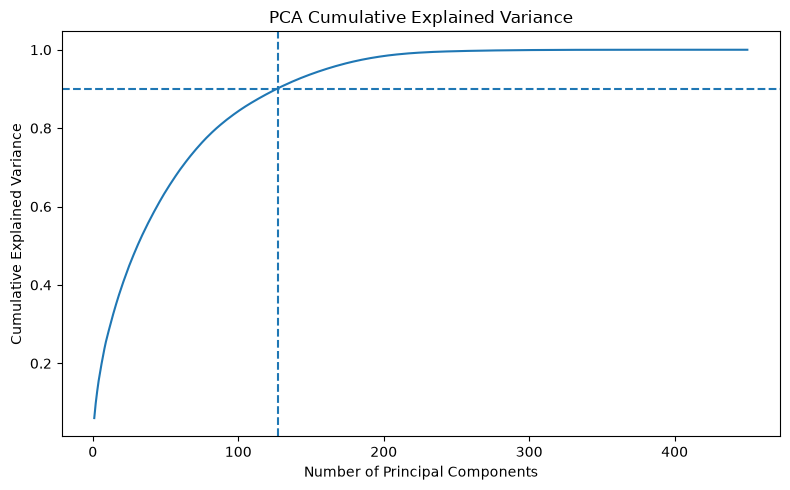

90% explained variance PC count: 127


In [49]:
from sklearn.decomposition import PCA

# 설명분산 그래프용 전체 PCA
pca_full = PCA()
pca_full.fit(X_train_scaled)

cumulative_variance_full = np.cumsum(
    pca_full.explained_variance_ratio_
)

# PCA 90%에서 사용한 PC 수
pc90_count = int(
    pca_results_df.loc[
        pca_results_df["Explained Variance"] == 0.90,
        "PC Count"
    ].iloc[0]
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance_full) + 1),
    cumulative_variance_full
)

# 90% 설명분산 기준
plt.axhline(
    y=0.90,
    linestyle="--"
)

# 선택된 PC 수 = 127
plt.axvline(
    x=pc90_count,
    linestyle="--"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "pca_cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("90% explained variance PC count:", pc90_count)

In [35]:
pca_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    random_state=42
)

start_time = time.perf_counter()

pca_model.fit(
    X_train_pca,
    y_train
)

pca_model_train_time = (
    time.perf_counter() - start_time
)

# 예측
y_pred_pca = pca_model.predict(
    X_test_pca
)

# Fail(1) 확률
fail_idx_pca = list(
    pca_model.classes_
).index(1)

y_prob_pca = pca_model.predict_proba(
    X_test_pca
)[:, fail_idx_pca]

print("PCA + Logistic Regression 학습 완료")
print(
    "Logistic 학습 시간:",
    round(pca_model_train_time, 4),
    "초"
)

PCA + Logistic Regression 학습 완료
Logistic 학습 시간: 0.0533 초


In [36]:
pca_accuracy = accuracy_score(
    y_test,
    y_pred_pca
)

pca_bal_acc = balanced_accuracy_score(
    y_test,
    y_pred_pca
)

pca_recall = recall_score(
    y_test,
    y_pred_pca,
    pos_label=1
)

pca_f1 = f1_score(
    y_test,
    y_pred_pca,
    pos_label=1
)

pca_auc = roc_auc_score(
    (y_test == 1).astype(int),
    y_prob_pca
)

print("=== PCA 적용 후 ===")
print(f"PC 개수             : {pca.n_components_}")
print(f"Accuracy            : {pca_accuracy:.4f}")
print(f"Balanced Accuracy   : {pca_bal_acc:.4f}")
print(f"Fail Recall         : {pca_recall:.4f}")
print(f"Fail F1-score       : {pca_f1:.4f}")
print(f"ROC-AUC             : {pca_auc:.4f}")
print(f"Logistic Train Time : {pca_model_train_time:.4f} sec")

=== PCA 적용 후 ===
PC 개수             : 160
Accuracy            : 0.7803
Balanced Accuracy   : 0.5286
Fail Recall         : 0.2381
Fail F1-score       : 0.1266
ROC-AUC             : 0.5636
Logistic Train Time : 0.0533 sec


In [37]:
cm_pca = confusion_matrix(
    y_test,
    y_pred_pca,
    labels=[-1, 1]
)

print("Confusion Matrix")
print(cm_pca)

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_pca,
        target_names=["Pass", "Fail"],
        digits=4
    )
)

Confusion Matrix
[[240  53]
 [ 16   5]]

Classification Report
              precision    recall  f1-score   support

        Pass     0.9375    0.8191    0.8743       293
        Fail     0.0862    0.2381    0.1266        21

    accuracy                         0.7803       314
   macro avg     0.5119    0.5286    0.5004       314
weighted avg     0.8806    0.7803    0.8243       314



## 5. PCA 설명분산 비율별 성능 비교

PCA에서 보존하는 설명분산 비율에 따라
주성분 수와 분류 성능이 어떻게 달라지는지 비교한다.

In [38]:
variance_levels = [0.80, 0.90, 0.95, 0.99]

pca_results = []

for variance in variance_levels:

    # PCA
    temp_pca = PCA(
        n_components=variance,
        svd_solver="full"
    )

    X_train_temp = temp_pca.fit_transform(
        X_train_scaled
    )

    X_test_temp = temp_pca.transform(
        X_test_scaled
    )

    # 동일 Logistic Regression
    temp_model = LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    )

    start = time.perf_counter()

    temp_model.fit(
        X_train_temp,
        y_train
    )

    train_time = time.perf_counter() - start

    pred = temp_model.predict(
        X_test_temp
    )

    fail_idx = list(
        temp_model.classes_
    ).index(1)

    prob = temp_model.predict_proba(
        X_test_temp
    )[:, fail_idx]

    pca_results.append({
        "Explained Variance": variance,
        "PC Count": temp_pca.n_components_,
        "Accuracy": accuracy_score(
            y_test, pred
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "Fail Recall": recall_score(
            y_test, pred,
            pos_label=1
        ),
        "Fail F1": f1_score(
            y_test, pred,
            pos_label=1
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == 1).astype(int),
            prob
        ),
        "Train Time": train_time
    })

pca_results_df = pd.DataFrame(pca_results)

pca_results_df

,Explained Variance,PC Count,Accuracy,Balanced Accuracy,Fail Recall,Fail F1,ROC-AUC,Train Time
0,0.80,86,0.713376,0.492768,0.238095,0.100000,0.599870,0.017463
1,0.90,127,0.789809,0.533723,0.238095,0.131579,0.591094,0.028947
2,0.95,160,0.780255,0.528604,0.238095,0.126582,0.563627,0.026249
3,0.99,215,0.799363,0.516740,0.190476,0.112676,0.616772,0.029215


In [39]:
baseline_row = pd.DataFrame([{
    "Method": "Without PCA",
    "Features": 450,
    "Accuracy": baseline_accuracy,
    "Balanced Accuracy": baseline_bal_acc,
    "Fail Recall": baseline_recall,
    "Fail F1": baseline_f1,
    "ROC-AUC": baseline_auc,
    "Train Time": baseline_train_time
}])

pca95_row = pd.DataFrame([{
    "Method": "PCA 95%",
    "Features": pca.n_components_,
    "Accuracy": pca_accuracy,
    "Balanced Accuracy": pca_bal_acc,
    "Fail Recall": pca_recall,
    "Fail F1": pca_f1,
    "ROC-AUC": pca_auc,
    "Train Time": pca_model_train_time
}])

comparison_df = pd.concat(
    [baseline_row, pca95_row],
    ignore_index=True
)

comparison_df

,Method,Features,Accuracy,Balanced Accuracy,Fail Recall,Fail F1,ROC-AUC,Train Time
0,Without PCA,450,0.840764,0.538924,0.190476,0.137931,0.620348,0.096634
1,PCA 95%,160,0.780255,0.528604,0.238095,0.126582,0.563627,0.053343


In [40]:
# PCA 후보 중 90% 결과 가져오기
pca90_result = pca_results_df[
    pca_results_df["Explained Variance"] == 0.90
].iloc[0]

final_comparison = pd.DataFrame([
    {
        "Method": "Without PCA",
        "Features": 450,
        "Accuracy": baseline_accuracy,
        "Balanced Accuracy": baseline_bal_acc,
        "Fail Recall": baseline_recall,
        "Fail F1": baseline_f1,
        "ROC-AUC": baseline_auc,
        "Train Time": baseline_train_time
    },
    {
        "Method": "PCA 90%",
        "Features": int(pca90_result["PC Count"]),
        "Accuracy": pca90_result["Accuracy"],
        "Balanced Accuracy": pca90_result["Balanced Accuracy"],
        "Fail Recall": pca90_result["Fail Recall"],
        "Fail F1": pca90_result["Fail F1"],
        "ROC-AUC": pca90_result["ROC-AUC"],
        "Train Time": pca90_result["Train Time"]
    }
])

final_comparison.round(4)

,Method,Features,Accuracy,Balanced Accuracy,Fail Recall,Fail F1,ROC-AUC,Train Time
0,Without PCA,450,0.8408,0.5389,0.1905,0.1379,0.6203,0.0966
1,PCA 90%,127,0.7898,0.5337,0.2381,0.1316,0.5911,0.0289


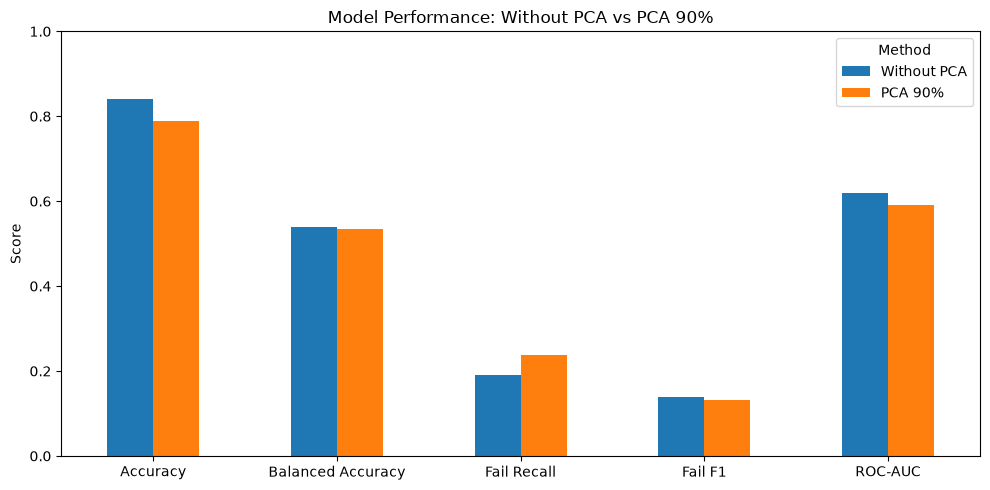

In [46]:
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Fail Recall",
    "Fail F1",
    "ROC-AUC"
]

plot_df = final_comparison.set_index("Method")[metrics].T

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Score")
plt.title("Model Performance: Without PCA vs PCA 90%")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Method")

plt.tight_layout()
plt.savefig(
    RESULT_DIR / "pca_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 6. 결론

- 원본 SECOM 데이터는 590개의 센서 변수를 포함하였다.
- Train 데이터 기준 결측률 50% 이상 변수 24개와 상수 변수 116개를 제거하여 450개 변수를 사용하였다.
- PCA 설명분산 비율을 80%, 90%, 95%, 99%로 비교하였다.
- 이 중 PCA 90%는 450개 변수를 127개의 주성분으로 축소하여 약 71.8%의 차원 감소를 달성하였다.
- PCA 적용 후 Balanced Accuracy는 0.5389에서 0.5337로 거의 유지되었다.
- Fail Recall은 0.1905에서 0.2381로 증가하였다.
- 반면 Accuracy, F1-score, ROC-AUC는 감소하였다.
- 따라서 본 데이터에서는 PCA가 전체 예측 성능을 향상시키지는 않았지만,
  상당한 차원 축소와 모델 학습 효율 개선이 가능함을 확인하였다.
- PCA는 라벨을 사용하지 않고 분산이 큰 방향을 보존하기 때문에,
  분산이 작지만 Fail 판별에 중요한 정보가 일부 손실되었을 가능성이 있다.

In [42]:
# 결과표 저장
RESULT_DIR = PROJECT_DIR / "results"
RESULT_DIR.mkdir(exist_ok=True)

final_comparison.round(4).to_csv(
    RESULT_DIR / "pca_final_comparison.csv",
    index=False
)

pca_results_df.round(4).to_csv(
    RESULT_DIR / "pca_variance_comparison.csv",
    index=False
)

print("결과표 저장 완료")

결과표 저장 완료


In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

print("Library load complete")

Library load complete


In [2]:
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data" / "raw"
RESULT_DIR = BASE_DIR / "results"

RESULT_DIR.mkdir(exist_ok=True)

X = pd.read_csv(
    DATA_DIR / "secom.data",
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    DATA_DIR / "secom_labels.data",
    sep=r"\s+",
    header=None
)

y = labels.iloc[:, 0].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nLabel distribution")
print(y.value_counts())

print("\nLabel ratio")
print(y.value_counts(normalize=True))

X shape: (1567, 590)
y shape: (1567,)

Label distribution
0
-1    1463
 1     104
Name: count, dtype: int64

Label ratio
0
-1    0.933631
 1    0.066369
Name: proportion, dtype: float64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

print("\nTrain labels")
print(y_train.value_counts())

print("\nTest labels")
print(y_test.value_counts())

Train shape: (1253, 590)
Test shape : (314, 590)

Train labels
0
-1    1170
 1      83
Name: count, dtype: int64

Test labels
0
-1    293
 1     21
Name: count, dtype: int64
